# V2 run: stronger augmentation + CutMix (EfficientNetV2-S only; compare with run1)
# Image classification on Kaggle: baseline vs EfficientNetV2-S
**Before Run All:** (1) attach your dataset as an input, (2) Settings → Accelerator → GPU, (3) Settings → Internet → On.
Pipeline: verify images → group duplicates/augmented copies → leak-free train/val/test split → train baseline + main model → compare on validation → export.
Safe to re-run: checkpoints resume automatically. Change `CFG['experiment']` for a fresh run.

In [2]:
# Environment check: GPU, packages, and pretrained-weight download (needs Internet ON).
import sys, subprocess, importlib
for pkg, mod in [('torch', 'torch'), ('torchvision', 'torchvision'), ('scikit-learn', 'sklearn'),
                 ('scipy', 'scipy'), ('Pillow', 'PIL'), ('matplotlib', 'matplotlib')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print('Installing missing package:', pkg)
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
import torch, torchvision
print('torch', torch.__version__, '| torchvision', torchvision.__version__)
print('GPU available:', torch.cuda.is_available(),
      [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
if not torch.cuda.is_available():
    print('WARNING: no GPU. In the right-hand Settings panel set Accelerator to a GPU, then re-run. CPU training will be very slow.')
from torchvision.models import EfficientNet_V2_S_Weights, MobileNet_V3_Small_Weights
try:
    EfficientNet_V2_S_Weights.IMAGENET1K_V1.get_state_dict(progress=False)
    MobileNet_V3_Small_Weights.IMAGENET1K_V1.get_state_dict(progress=False)
    print('Pretrained weights downloaded OK (Internet is on).')
except Exception as exc:
    raise RuntimeError('Could not download pretrained weights. Turn Internet ON in the notebook Settings '
                       '(it may ask for phone verification), then re-run this cell.') from exc

torch 2.11.0+cu128 | torchvision 0.26.0+cu128
GPU available: True ['Tesla T4', 'Tesla T4']
Pretrained weights downloaded OK (Internet is on).


## Helpers and dataset discovery

In [3]:
"""Shared imports, config, helpers and dataset-layout discovery.

Embedded first in the notebook. No heavy work happens on import.
"""
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')  # needed for deterministic CUDA ops
import json
import hashlib
from pathlib import Path
import numpy as np

SPLITS = ['train', 'val', 'test']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}
CLASSES = []   # filled in place by discover_dataset(); never rebind this name
LAYOUT = {}    # filled in place by discover_dataset(): {'kind': 'split'|'flat', 'dirs': {split: folder}}



def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str), encoding='utf-8')


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b''):
            digest.update(chunk)
    return digest.hexdigest()


def is_supported_image(path):
    return Path(path).suffix.lower() in IMAGE_EXTS


def environment_paths():
    """Return (on_kaggle, input_roots, output_root)."""
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.is_dir():
        inputs = sorted(p for p in kaggle_input.iterdir() if p.is_dir())
        output_root = Path('/kaggle/working')
        return True, inputs, output_root
    output_root = Path.cwd() / 'outputs'
    output_root.mkdir(exist_ok=True)
    return False, [], output_root


def _has_images(folder):
    for _, _, files in os.walk(folder):
        if any(is_supported_image(f) for f in files):
            return True
    return False


def _walk_limited(base, max_depth):
    base = Path(base)
    base_depth = len(base.parts)
    for dirpath, dirs, _ in os.walk(base):
        if len(Path(dirpath).parts) - base_depth >= max_depth:
            dirs[:] = []
        yield Path(dirpath), list(dirs)


def _tree_preview(roots, limit=40):
    lines = []
    for base in roots:
        for folder, dirs in _walk_limited(base, 3):
            lines.append(str(folder) + '  (' + ', '.join(sorted(dirs)[:8]) + (', ...' if len(dirs) > 8 else '') + ')')
            if len(lines) >= limit:
                return '\n'.join(lines)
    return '\n'.join(lines)


def discover_dataset(inputs, output_root, data_root=None):
    """Find the image dataset, fill CLASSES and LAYOUT in place, print what was found, return its root.

    Supported layouts (class folders hold the images, possibly nested):
      split layout: <root>/train/<class>/..., optional val|valid|validation, optional test|testing
      flat layout:  <root>/<class>/...   (a test set is carved out by group later)
    """
    search = [Path(data_root)] if data_root else (list(inputs) if inputs else [Path.cwd()])
    split_hit, flat_hits = None, []
    for base in search:
        for folder, dirs in _walk_limited(base, 6):
            names = {d.lower(): d for d in dirs}
            if 'train' in names and split_hit is None:
                has_other = any(k in names for k in ('test', 'testing', 'val', 'valid', 'validation'))
                if has_other and _has_images(folder / names['train']):
                    split_hit = (folder, names)
            elif 'train' not in names and len(dirs) >= 2 and not flat_hits:
                good = [d for d in dirs if _has_images(folder / d)]
                if len(good) >= 2 and len(good) == len(dirs):
                    flat_hits.append((folder, sorted(good)))
        if split_hit:
            break
    if split_hit:
        root, names = split_hit
        dirs = {'train': names['train']}
        for key, aliases in (('val', ('val', 'valid', 'validation')), ('test', ('test', 'testing'))):
            for alias in aliases:
                if alias in names:
                    dirs[key] = names[alias]
                    break
        classes = sorted(d.name for d in (root / dirs['train']).iterdir() if d.is_dir())
        for key, folder in dirs.items():
            found = sorted(d.name for d in (root / folder).iterdir() if d.is_dir())
            if found != classes:
                raise ValueError(f'Class folders differ in {folder}: {found} vs train {classes}')
        layout = {'kind': 'split', 'dirs': dirs}
    elif flat_hits:
        root, classes = flat_hits[0]
        layout = {'kind': 'flat', 'dirs': {'train': ''}}
    else:
        raise FileNotFoundError('Could not find an image dataset. Looked under: ' + ', '.join(map(str, search))
                                + '\nFolders seen:\n' + _tree_preview(search)
                                + '\nSet CFG["data_root"] to the folder that holds the class folders.')
    CLASSES[:] = classes
    LAYOUT.clear()
    LAYOUT.update(layout)
    print('Dataset root:', root)
    print('Layout:', layout['kind'], layout['dirs'])
    print('Classes (' + str(len(classes)) + '):', classes)
    if len(classes) < 2:
        raise ValueError('Need at least 2 classes')
    return root

## Config (edit here)
Image size, batch size and epochs are assumptions, not measured limits. If you hit GPU out-of-memory, use a **new** experiment name and lower `batch_size` (raise `accumulation_steps` to keep the effective batch).

In [4]:
# Plain JSON types only (the config is stored inside checkpoints and loaded with weights_only=True).
CFG = {
    'experiment': 'run2',          # new name = new run; same name = resume
    'data_root': None,             # None = auto-discover under /kaggle/input
    'seed': 42,
    'validation_fraction': 0.15,   # ~1/round(1/x) folds, so 0.15 gives about 14%
    'test_fraction': 0.15,         # only used if the dataset has no test folder
    'phash_distance': 2,           # 0-8; lower = fewer images grouped as near-duplicates
    'image_size': 384,             # EfficientNetV2-S
    'batch_size': 16,
    'accumulation_steps': 2,       # effective batch = 32
    'epochs': 30,
    'baseline_image_size': 224,    # MobileNetV3-Small baseline
    'baseline_batch_size': 64,
    'baseline_epochs': 12,
    'learning_rate': 1e-4,         # backbone
    'head_lr_multiplier': 10.0,    # classifier head LR = learning_rate * this
    'warmup_epochs': 2,            # epochs with frozen backbone (head only)
    'min_lr_ratio': 0.05,
    'weight_decay': 1e-2,
    'dropout': 0.3,
    'label_smoothing': 0.05,
    'gradient_clip': 1.0,
    'early_stopping_patience': 7,
    'mixed_precision': True,
    'workers': None,               # None = auto (2 on Kaggle)
    'log_every': 50,
    'auto_resume': True,
    'resume_paths': {},            # e.g. {'efficientnet_v2_s': '/kaggle/input/.../latest.pt'}
    'evaluate_test': True,
    'models': ['efficientnet_v2_s'],   # which models to train; baseline first
    'augmentation': 'strong',       # 'basic' or 'strong' (crop/zoom, flips, shear, erasing; colour-safe)
    'cutmix_prob': 0.5,            # 0 = off; e.g. 0.5 = CutMix on half of the training batches
    'cutmix_alpha': 1.0,
    'erasing_prob': 0.25,          # only used when augmentation == 'strong'
    'rotation': 15,
    'brightness': 0.2,
    'contrast': 0.2,
    'saturation': 0.1,
    'mean': [0.485, 0.456, 0.406],
    'std': [0.229, 0.224, 0.225],
}

## Dataset scan and grouped splitting

In [5]:
"""[INFERRED] Read-only decoding, grouping and stratified group splitting.

Requires data_utils definitions (embedded in the notebook). No work on import.
"""
import re
import collections
import warnings
import numpy as np
from PIL import Image, ImageOps
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold


class UnionFind:
    def __init__(self, size):
        self.parent = list(range(size))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)


def phash(image):
    gray = np.asarray(image.convert('L').resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    low = dctn(gray, type=2, norm='ortho')[:8, :8].flatten()
    bits = low > np.median(low[1:])
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return value


def phash_edges(values, threshold):
    """Pigeonhole index: all pairs within threshold have a shared exact band."""
    if not 0 <= threshold <= 8:
        raise ValueError('phash_distance must be between 0 and 8')
    bands = threshold + 1
    buckets = [collections.defaultdict(list) for _ in range(bands)]
    for index, value in enumerate(values):
        candidates, keys = set(), []
        for band in range(bands):
            start, stop = 64 * band // bands, 64 * (band + 1) // bands
            key = (value >> start) & ((1 << (stop - start)) - 1)
            keys.append(key)
            candidates.update(buckets[band].get(key, []))
        for other in sorted(candidates):
            distance = (value ^ values[other]).bit_count()
            if distance <= threshold:
                yield other, index, distance
        for band, key in enumerate(keys):
            buckets[band][key].append(index)


def pick_group_fold(indices, rows, fraction, seed, what, output, edges, exclusions):
    """Hold out ~fraction of groups, stratified by class. Fold chosen by size/class balance only."""
    y = np.array([rows[i]['label'] for i in indices])
    group_ids = np.array([rows[i]['group'] for i in indices])
    group_counts = {c: len({rows[i]['group'] for i in indices if rows[i]['label'] == c})
                    for c in range(len(CLASSES))}
    n_folds = round(1 / fraction)
    if n_folds < 2 or any(n < n_folds for n in group_counts.values()):
        write_json(output / 'grouping_review.json', {'rows': rows, 'edges': edges, 'exclusions': exclusions})
        raise ValueError(f'Need >= {n_folds} independent groups per class for the {what} split. '
                         f'Found {group_counts}. Review grouping_review.json; '
                         'try a lower phash_distance rather than relaxing safeguards.')
    splitter = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    counts = np.bincount(y, minlength=len(CLASSES))
    candidates = []
    for fold, (rest_idx, held_idx) in enumerate(splitter.split(np.zeros(len(y)), y, group_ids)):
        held_counts = np.bincount(y[held_idx], minlength=len(CLASSES))
        rest_counts = np.bincount(y[rest_idx], minlength=len(CLASSES))
        if min(held_counts) == 0 or min(rest_counts) == 0:
            continue
        error = float(np.mean(np.abs(held_counts / counts - fraction)))
        candidates.append((error, fold, rest_idx, held_idx))
    if not candidates:
        raise ValueError(f'No stratified group fold contains all classes for the {what} split.')
    _, fold, rest_idx, held_idx = min(candidates, key=lambda item: item[:2])
    return [indices[i] for i in rest_idx], [indices[i] for i in held_idx], fold


def scan_and_split(cfg):
    kaggle, inputs, output_root = environment_paths()
    if Path(cfg['experiment']).name != cfg['experiment'] or cfg['experiment'] in {'.', '..'}:
        raise ValueError('experiment must be a single directory name')
    output = output_root / cfg['experiment']
    output.mkdir(parents=True, exist_ok=True)
    root = discover_dataset(inputs, output_root, cfg['data_root'])
    rows, corrupt, scan_warnings = [], [], []
    for split, folder in LAYOUT['dirs'].items():
        for label, cls in enumerate(CLASSES):
            base = root / folder / cls
            if not base.is_dir():
                continue
            for path in sorted(base.rglob('*')):
                if not path.is_file() or not is_supported_image(path):
                    continue
                relative = path.relative_to(root).as_posix()
                try:
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter('always')
                        with Image.open(path) as im:
                            im.verify()
                        with Image.open(path) as im:
                            im.load()
                            rgb = ImageOps.exif_transpose(im).convert('RGB')
                            pixel_hash = hashlib.sha256(
                                str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                            perceptual = phash(rgb)
                            width, height = rgb.size
                        scan_warnings.extend({'path': relative, 'warning': str(w.message)} for w in caught)
                    rows.append({'path': relative, 'original_split': split, 'class': cls, 'label': label,
                                 'width': width, 'height': height, 'sha256': sha256_file(path),
                                 'pixel_sha256': pixel_hash, 'phash': f'{perceptual:016x}',
                                 'lineage': cls + '/' + re.sub(r'^(?:aug_\d+_)+', '', path.stem)})
                except Exception as exc:
                    corrupt.append({'path': relative, 'error': type(exc).__name__ + ': ' + str(exc)})
                if (len(rows) + len(corrupt)) % 1000 == 0:
                    print('Decoded:', len(rows), 'skipped:', len(corrupt), flush=True)
    write_json(output / 'corrupt_images.json', corrupt)
    write_json(output / 'image_warnings.json', scan_warnings)
    if not rows:
        raise ValueError('No readable JPEG/PNG images. See corrupt_images.json')
    print('Classes:', CLASSES)
    print('Readable counts:', dict(collections.Counter(r['class'] for r in rows)))
    print('Image widths:', min(r['width'] for r in rows), 'to', max(r['width'] for r in rows))
    print('Image heights:', min(r['height'] for r in rows), 'to', max(r['height'] for r in rows))
    print('Skipped corrupt images:', len(corrupt), 'log:', output / 'corrupt_images.json')
    groups = UnionFind(len(rows))
    edges = []
    for key in ['sha256', 'pixel_sha256', 'lineage']:
        seen = {}
        for i, row in enumerate(rows):
            value = row[key]
            if value in seen:
                other = seen[value]
                groups.union(other, i)
                edges.append({'a': other, 'b': i, 'reason': key})
            else:
                seen[value] = i
    for a, b, distance in phash_edges([int(r['phash'], 16) for r in rows], cfg['phash_distance']):
        groups.union(a, b)
        edges.append({'a': a, 'b': b, 'reason': 'phash', 'distance': distance})
    bygroup = collections.defaultdict(list)
    for i, row in enumerate(rows):
        row['group'] = groups.find(i)
        bygroup[row['group']].append(i)
    exclusions, pool_indices, test_indices = [], [], []
    # Conflict groups are uncertain labels, NOT corrected automatically.
    # Test-linked training/validation groups are excluded from the development pool.
    for group, indices in bygroup.items():
        labels = {rows[i]['label'] for i in indices}
        has_test = any(rows[i]['original_split'] == 'test' for i in indices)
        for i in indices:
            if len(labels) > 1:
                exclusions.append({'index': i, 'path': rows[i]['path'], 'reason': 'group_label_conflict'})
            elif has_test:
                if rows[i]['original_split'] == 'test':
                    test_indices.append(i)
                else:
                    exclusions.append({'index': i, 'path': rows[i]['path'], 'reason': 'group_overlaps_test'})
            else:
                pool_indices.append(i)
    pool_indices.sort()
    test_indices.sort()
    sizes = sorted((len(v) for v in bygroup.values()), reverse=True)
    group_stats = {'groups': len(sizes), 'groups_with_2plus_images': sum(n > 1 for n in sizes),
                   'largest_groups': sizes[:10]}
    print('Group sizes:', json.dumps(group_stats))
    print('Excluded:', len(exclusions), 'of', len(rows), 'readable images')
    if len(exclusions) > 0.2 * len(rows):
        print('WARNING: >20% of images excluded. Lower CFG["phash_distance"] (try 0) and re-run with a new experiment name.')
    test_source = 'original'
    if not test_indices:
        test_source = 'carved_from_development_pool'
        print('No test folder found: carving a group-wise test set from the pool.')
        pool_indices, test_indices, _ = pick_group_fold(pool_indices, rows, cfg['test_fraction'], cfg['seed'],
                                                        'test', output, edges, exclusions)
    train_list, val_list, fold = pick_group_fold(pool_indices, rows, cfg['validation_fraction'], cfg['seed'],
                                                 'validation', output, edges, exclusions)
    assignments = {'train': train_list, 'val': val_list, 'test': test_indices}
    if any(not any(rows[i]['label'] == c for i in test_indices) for c in range(len(CLASSES))):
        raise ValueError('Filtered test set is missing one or more classes; inspect grouping before evaluation.')
    sets = {s: {rows[i]['group'] for i in ix} for s, ix in assignments.items()}
    if any(sets[a] & sets[b] for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]):
        raise AssertionError('Grouping implementation error: overlapping split groups')
    payload = {'rows': rows, 'splits': assignments, 'exclusions': exclusions, 'corrupt': corrupt,
               'seed': cfg['seed'], 'phash_distance': cfg['phash_distance'],
               'validation_fraction_requested': cfg['validation_fraction'], 'selected_fold': fold,
               'test_source': test_source, 'classes': CLASSES}
    fingerprint = hashlib.sha256(json.dumps(payload, sort_keys=True, separators=(',', ':')).encode()).hexdigest()
    payload['fingerprint'] = fingerprint
    manifest_path = output / 'split_manifest.json'
    if manifest_path.exists():
        prior = json.loads(manifest_path.read_text())
        if prior['fingerprint'] != fingerprint:
            raise ValueError('Dataset/split changed within an existing experiment. Use a new experiment name.')
    write_json(manifest_path, payload)
    write_json(output / 'grouping_edges.json', edges)
    write_json(output / 'excluded_images.json', exclusions)
    summaries = {}
    for split, indices in assignments.items():
        summaries[split] = {'images': len(indices), 'groups': len(sets[split]),
                            'class_counts': {c: sum(rows[i]['class'] == c for i in indices) for c in CLASSES}}
        print(split, json.dumps(summaries[split]))
    write_json(output / 'data_summary.json', {'original_readable_images': len(rows),
        'corrupt_images': len(corrupt), 'excluded_images': len(exclusions), 'splits': summaries,
        'test_source': test_source, 'group_stats': group_stats, 'layout': LAYOUT,
        'grouping_limit': 'Detected identity/lineage/perceptual groups only; no patient/source IDs available.'})
    print('Split fingerprint:', fingerprint)
    print('Excluded from this run (original files untouched):', len(exclusions))
    return {'kaggle': kaggle, 'inputs': inputs, 'output': output, 'root': root,
            'rows': rows, 'splits': assignments, 'fingerprint': fingerprint}

## Training code

In [6]:
"""[INFERRED] Transfer learning comparison: cheap baseline then main candidate.

Definitions only; embedded after discovery/splitting code in the browser notebook.
"""
import math
import random
import time
import csv
import shutil
import platform
import gc
from contextlib import nullcontext
from importlib.metadata import version
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import (efficientnet_v2_s, EfficientNet_V2_S_Weights,
                                mobilenet_v3_small, MobileNet_V3_Small_Weights)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def worker_seed(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def runtime():
    return {'python': platform.python_version(), 'packages': {p: version(p) for p in
        ['torch', 'torchvision', 'numpy', 'Pillow', 'scipy', 'scikit-learn', 'matplotlib']},
        'cuda': torch.version.cuda,
        'gpus': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}


def model_for(name, dropout, pretrained):
    if name == 'efficientnet_v2_s':
        model = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[0] = nn.Dropout(dropout)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASSES))
    elif name == 'mobilenet_v3_small':
        model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
        model.classifier[2] = nn.Dropout(dropout)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(CLASSES))
    else:
        raise ValueError('Unknown model: ' + name)
    return model


def transform_for(size, cfg, augment=False):
    interp = InterpolationMode.BILINEAR
    if augment and cfg['augmentation'] == 'strong':
        # Geometric + mild colour changes only: skin colour is a useful cue, so no solarize/posterize/hue shifts.
        operations = [transforms.RandomResizedCrop((size, size), scale=(0.5, 1.0), ratio=(0.8, 1.25),
                                                   interpolation=interp, antialias=True),
                      transforms.RandomHorizontalFlip(0.5), transforms.RandomVerticalFlip(0.5),
                      transforms.RandomRotation(cfg['rotation']),
                      transforms.RandomAffine(degrees=0, shear=10),
                      transforms.ColorJitter(cfg['brightness'], cfg['contrast'], cfg['saturation'])]
        tail = [transforms.ToTensor(), transforms.Normalize(cfg['mean'], cfg['std']),
                transforms.RandomErasing(p=cfg['erasing_prob'], scale=(0.02, 0.15), value=0)]
        return transforms.Compose(operations + tail)
    # Whole-image square resize avoids assuming the lesion is centered.
    operations = [transforms.Resize((size, size), interpolation=interp, antialias=True)]
    if augment:
        operations += [transforms.RandomHorizontalFlip(0.5), transforms.RandomRotation(cfg['rotation']),
                       transforms.ColorJitter(cfg['brightness'], cfg['contrast'], cfg['saturation'])]
    return transforms.Compose(operations + [transforms.ToTensor(),
        transforms.Normalize(cfg['mean'], cfg['std'])])


def cutmix_batch(images, labels, alpha):
    lam = float(np.random.beta(alpha, alpha))
    index = torch.randperm(images.size(0), device=images.device)
    h, w = images.shape[2], images.shape[3]
    cut = math.sqrt(1.0 - lam)
    ch, cw = int(h * cut), int(w * cut)
    cy, cx = int(np.random.randint(h)), int(np.random.randint(w))
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, h)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, w)
    images[:, :, y1:y2, x1:x2] = images[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / float(h * w))
    return images, labels, labels[index], lam


class BiteDataset(Dataset):
    def __init__(self, context, split, transform):
        self.root = context['root']
        self.rows = [context['rows'][i] for i in context['splits'][split]]
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        try:
            with Image.open(self.root / row['path']) as image:
                image.load()
                tensor = self.transform(ImageOps.exif_transpose(image).convert('RGB'))
        except Exception as exc:
            # Do not silently change a frozen split after the preflight corruption scan.
            raise RuntimeError('Image changed/unreadable after scan: ' + row['path']) from exc
        return tensor, row['label']


def loaders_for(context, cfg, size, batch_size):
    workers = cfg['workers']
    if workers is None:
        workers = min(2, max(0, (os.cpu_count() or 1) - 1)) if context['kaggle'] else 0
    generator = torch.Generator()
    data, loaders = {}, {}
    for split in SPLITS:
        data[split] = BiteDataset(context, split, transform_for(size, cfg, split == 'train'))
        kwargs = {'batch_size': batch_size, 'num_workers': workers, 'shuffle': split == 'train',
                  'pin_memory': torch.cuda.is_available(), 'worker_init_fn': worker_seed,
                  'generator': generator if split == 'train' else torch.Generator().manual_seed(cfg['seed']),
                  'persistent_workers': False}
        if workers:
            kwargs['prefetch_factor'] = 2
        loaders[split] = DataLoader(data[split], **kwargs)
    print('Workers:', workers, 'batch size:', batch_size, 'input:', size)
    return data, loaders, generator


def metrics_for(y, prediction):
    result = {'accuracy': float(accuracy_score(y, prediction))}
    for average in ['macro', 'weighted']:
        p, r, f, _ = precision_recall_fscore_support(y, prediction, labels=range(len(CLASSES)),
                                                    average=average, zero_division=0)
        result.update({average + '_precision': float(p), average + '_recall': float(r),
                       average + '_f1': float(f)})
    return result


def atomic_save(value, path):
    temp = path.with_name(path.name + '.tmp')
    torch.save(value, temp)
    os.replace(temp, path)


def cpu_weights(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def checkpoint_path(context, cfg, name):
    requested = cfg['resume_paths'].get(name)
    if requested:
        path = Path(requested)
        if not path.is_file():
            raise FileNotFoundError(f'Resume checkpoint missing: {path}')
        return path
    local = context['output'] / name / 'latest.pt'
    if not cfg['auto_resume']:
        if local.exists():
            raise FileExistsError('Run already exists; use auto_resume or a new experiment name')
        return None
    if local.is_file():
        return local
    # Bounded lookup: never crawl the (large) image dataset.
    patterns = [f"{cfg['experiment']}/{name}/latest.pt", f"*/{cfg['experiment']}/{name}/latest.pt",
                f"*/*/{cfg['experiment']}/{name}/latest.pt"]
    candidates = sorted({p for root in context['inputs'] for pattern in patterns for p in root.glob(pattern)})
    if len(candidates) > 1:
        raise ValueError(f'Multiple {name} resume files: {candidates}. Set resume_paths explicitly.')
    if candidates:
        return candidates[0]
    print('No retained checkpoint for', name, '- starting fresh.')
    return None


def make_plots(history, output):
    write_json(output / 'history.json', history)
    with (output / 'history.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    for key in ['loss', 'accuracy', 'macro_f1']:
        fig, ax = plt.subplots(figsize=(8, 4))
        for split in ['train', 'val']:
            ax.plot([h['epoch'] for h in history], [h[split + '_' + key] for h in history], label=split)
        ax.set(xlabel='Epoch', ylabel=key)
        ax.legend()
        fig.tight_layout()
        fig.savefig(output / (key + '.png'), dpi=150)
        plt.close(fig)


def save_evaluation(y, probs, rows, output, split):
    prediction = probs.argmax(axis=1)
    result = metrics_for(y, prediction)
    report = classification_report(y, prediction, labels=list(range(len(CLASSES))),
                                   target_names=CLASSES, zero_division=0, output_dict=True)
    write_json(output / (split + '_per_class.json'), report)
    print(split, classification_report(y, prediction, labels=list(range(len(CLASSES))),
                                      target_names=CLASSES, zero_division=0))
    matrix = confusion_matrix(y, prediction, labels=list(range(len(CLASSES))))
    with (output / (split + '_confusion.csv')).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.writer(stream)
        writer.writerow(['actual/predicted'] + CLASSES)
        writer.writerows([[c] + row.tolist() for c, row in zip(CLASSES, matrix)])
    totals, correct = matrix.sum(axis=1), np.diag(matrix)
    per_class = {c: (float(k) / float(n) if n else None) for c, k, n in zip(CLASSES, correct, totals)}
    with (output / (split + '_per_class_accuracy.csv')).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.writer(stream)
        writer.writerow(['class', 'correct', 'total', 'accuracy'])
        writer.writerows([[c, int(k), int(n), per_class[c]] for c, k, n in zip(CLASSES, correct, totals)])
    print(f'{split} per-class accuracy (correct / total):')
    for c, k, n in zip(CLASSES, correct, totals):
        print(f'  {c:<30} {int(k):>5} / {int(n):<5} = {100 * per_class[c] if n else float("nan"):6.2f}%')
    result['per_class_accuracy'] = per_class
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(CLASSES, [100 * (v or 0) for v in per_class.values()])
    ax.set(ylabel='Accuracy (%)', ylim=(0, 100), title=split + ' per-class accuracy')
    ax.tick_params(axis='x', rotation=75)
    fig.tight_layout()
    fig.savefig(output / (split + '_per_class_accuracy.png'), dpi=150)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=75, ha='right')
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set(xlabel='Predicted', ylabel='Actual', title=split)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center', fontsize=8)
    fig.tight_layout()
    fig.savefig(output / (split + '_confusion.png'), dpi=150)
    plt.close(fig)
    np.savez_compressed(output / (split + '_predictions.npz'), targets=y, probabilities=probs,
                        paths=np.array([r['path'] for r in rows]))
    return result


def epoch_pass(model, loader, loss_fn, device, cfg, optimizer=None, scaler=None,
               accum=1, head_only=False, use_amp=False):
    training = optimizer is not None
    model.train(training)
    if training and head_only:
        model.features.eval()  # freeze pretrained BatchNorm statistics during warm-up
    loss_sum, total, targets, scores = 0.0, 0, [], []
    if training:
        optimizer.zero_grad(set_to_none=True)
    with torch.set_grad_enabled(training):
        for step, (images, labels) in enumerate(loader):
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            mixed = None
            if training and cfg['cutmix_prob'] > 0 and np.random.rand() < cfg['cutmix_prob']:
                images, labels_a, labels_b, lam = cutmix_batch(images, labels, cfg['cutmix_alpha'])
                mixed = (labels_a, labels_b, lam)
            amp_context = torch.autocast('cuda', dtype=torch.float16) if use_amp else nullcontext()
            with amp_context:
                logits = model(images)
                if mixed:
                    losses = mixed[2] * loss_fn(logits, mixed[0]) + (1 - mixed[2]) * loss_fn(logits, mixed[1])
                else:
                    losses = loss_fn(logits, labels)
                batch_loss = losses.mean()
            if not torch.isfinite(batch_loss):
                raise FloatingPointError('Non-finite loss; retained checkpoint is last completed epoch.')
            if training:
                window_start = (step // accum) * accum * loader.batch_size
                window_samples = min(accum * loader.batch_size, len(loader.dataset) - window_start)
                # Correct scaling even when the last accumulation window is short.
                scaler.scale(losses.sum() / window_samples).backward()
                if (step + 1) % accum == 0 or step + 1 == len(loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['gradient_clip'])
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            loss_sum += float(losses.detach().sum())
            total += len(labels)
            targets.append(labels.detach().cpu().numpy())
            scores.append(logits.detach().float().softmax(1).cpu().numpy())
            if (step + 1) % cfg['log_every'] == 0 or step + 1 == len(loader):
                print(f'  {"train" if training else "eval"} {step+1}/{len(loader)} loss={loss_sum/total:.5f}', flush=True)
    y, probabilities = np.concatenate(targets), np.concatenate(scores)
    metrics = metrics_for(y, probabilities.argmax(1))
    metrics['loss'] = loss_sum / total
    return metrics, y, probabilities


def train_model(context, cfg, name):
    baseline = name == 'mobilenet_v3_small'
    size = cfg['baseline_image_size'] if baseline else cfg['image_size']
    batch = cfg['baseline_batch_size'] if baseline else cfg['batch_size']
    accum = 1 if baseline else cfg['accumulation_steps']
    epochs = cfg['baseline_epochs'] if baseline else cfg['epochs']
    output = context['output'] / name
    output.mkdir(exist_ok=True)
    saved_path = checkpoint_path(context, cfg, name)
    saved = torch.load(saved_path, map_location='cpu', weights_only=True) if saved_path else None
    if saved:
        print('Resuming:', saved_path)
        if (saved.get('format') != 'dermasentry_cv_v2' or saved['name'] != name
                or saved['split_fingerprint'] != context['fingerprint'] or saved['classes'] != CLASSES):
            raise ValueError('Resume format, model, class mapping, or dataset/split fingerprint mismatch')
        ignored = {'data_root', 'auto_resume', 'resume_paths', 'workers', 'log_every', 'evaluate_test', 'models'}
        differences = {k: (saved['config'].get(k), v) for k, v in cfg.items()
                       if k not in ignored and saved['config'].get(k) != v}
        if differences:
            raise ValueError('Resume config differs. Keep original recipe/epoch budget or use a new experiment: '
                             + str(differences))
    seed_all(cfg['seed'])
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    print(name, 'device:', device)
    data, loaders, generator = loaders_for(context, cfg, size, batch)
    counts = np.bincount([r['label'] for r in data['train'].rows], minlength=len(CLASSES))
    weights = 1.0 / np.sqrt(np.maximum(counts, 1))
    weights = np.clip(weights / weights.mean(), 0.5, 2.0)
    write_json(output / 'class_weights.json', dict(zip(CLASSES, weights.tolist())))
    try:
        model = model_for(name, cfg['dropout'], pretrained=saved is None).to(device)
    except Exception as exc:
        raise RuntimeError('Model setup failed. For fresh runs enable Internet for torchvision pretrained '
                           'weights. Inspect the underlying error; no random-initialization fallback.') from exc
    optimizer = torch.optim.AdamW([
        {'params': model.features.parameters(), 'lr': cfg['learning_rate']},
        {'params': model.classifier.parameters(), 'lr': cfg['learning_rate'] * cfg['head_lr_multiplier']}],
        weight_decay=cfg['weight_decay'])
    warmup = cfg['warmup_epochs']
    def schedule(epoch):
        if epoch < warmup:
            return (epoch + 1) / warmup
        fraction = (epoch - warmup) / max(1, epochs - warmup - 1)
        return cfg['min_lr_ratio'] + (1 - cfg['min_lr_ratio']) * (1 + math.cos(math.pi * min(fraction, 1))) / 2
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, schedule)
    amp = cfg['mixed_precision'] and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device),
                                  label_smoothing=cfg['label_smoothing'], reduction='none')
    history, best_state, best_score, best_epoch, bad, start = [], None, -1.0, -1, 0, 0
    info = runtime()
    if saved:
        model.load_state_dict(saved['weights'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        if saved['scaler']:
            scaler.load_state_dict(saved['scaler'])
        history, best_state, best_score = saved['history'], saved['best_weights'], saved['best_score']
        best_epoch, bad, start = saved['best_epoch'], saved['bad_epochs'], saved['epoch'] + 1
        if saved['runtime']['packages'] != info['packages']:
            print('WARNING: dependency versions changed since checkpoint; exact replay is not guaranteed.')
        if saved_path.resolve() != (output / 'latest.pt').resolve():
            shutil.copy2(saved_path, output / 'latest.pt')
        atomic_save(best_state, output / 'best.pt')
    write_json(output / 'runtime.json', info)
    write_json(output / 'config.json', cfg)
    for epoch in range(start, epochs):
        if bad >= cfg['early_stopping_patience']:
            print('Early stopping already satisfied. Keeping saved best model.')
            break
        seed_all(cfg['seed'] + epoch)
        generator.manual_seed(cfg['seed'] + epoch)
        head_only = epoch < warmup
        for parameter in model.features.parameters():
            parameter.requires_grad_(not head_only)
        phase = 'head_warmup' if head_only else 'full_finetune'
        start_time = time.perf_counter()
        print(f'{name}: epoch {epoch+1}/{epochs}, {phase}, LR {[g["lr"] for g in optimizer.param_groups]}')
        try:
            tm, _, _ = epoch_pass(model, loaders['train'], loss_fn, device, cfg, optimizer, scaler,
                                  accum, head_only, amp)
            vm, _, _ = epoch_pass(model, loaders['val'], loss_fn, device, cfg, use_amp=False)
        except torch.cuda.OutOfMemoryError as exc:
            raise RuntimeError('GPU memory exhausted. Save/download the retained checkpoint. '
                               'For a new experiment reduce batch_size, increase accumulation_steps, '
                               'or reduce image_size. Defaults are assumptions, not a measured memory guarantee.') from exc
        if vm['macro_f1'] > best_score:
            best_score, best_epoch, best_state, bad = vm['macro_f1'], epoch, cpu_weights(model), 0
        elif not head_only:
            bad += 1
        history.append({'epoch': epoch + 1, 'phase': phase, 'train_loss': tm['loss'], 'val_loss': vm['loss'],
                        'train_accuracy': tm['accuracy'], 'val_accuracy': vm['accuracy'],
                        'train_macro_f1': tm['macro_f1'], 'val_macro_f1': vm['macro_f1'],
                        'backbone_lr': optimizer.param_groups[0]['lr'],
                        'head_lr': optimizer.param_groups[1]['lr'],
                        'epoch_seconds': time.perf_counter() - start_time})
        scheduler.step()
        payload = {'format': 'dermasentry_cv_v2', 'name': name, 'config': cfg, 'classes': CLASSES,
                   'split_fingerprint': context['fingerprint'], 'epoch': epoch, 'weights': cpu_weights(model),
                   'best_weights': best_state, 'best_score': best_score, 'best_epoch': best_epoch,
                   'bad_epochs': bad, 'history': history, 'optimizer': optimizer.state_dict(),
                   'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(), 'runtime': info}
        atomic_save(payload, output / 'latest.pt')
        atomic_save(best_state, output / 'best.pt')
        make_plots(history, output)
        print(json.dumps(history[-1]), 'best epoch:', best_epoch + 1, flush=True)
    if best_state is None:
        raise RuntimeError('No completed epoch available to evaluate/export')
    model.load_state_dict(best_state)
    _, y, probs = epoch_pass(model, loaders['val'], loss_fn, device, cfg, use_amp=False)
    validation = save_evaluation(y, probs, data['val'].rows, output, 'val')
    result = {'name': name, 'image_size': size, 'batch_size': batch, 'best_epoch': best_epoch + 1,
              'validation': validation, 'parameter_count': sum(p.numel() for p in model.parameters()),
              'split_fingerprint': context['fingerprint'], 'clinical_validation': False,
              'runtime': info, 'metrics_unit': 'fraction'}
    write_json(output / 'metrics.json', result)
    make_plots(history, output)
    del model, optimizer, scheduler, scaler, saved, best_state, loaders, data
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def compare_models(context, cfg, results):
    # Freeze the winner on validation before reading either model's test predictions.
    winner = max(results, key=lambda result: result['validation']['macro_f1'])['name']
    selection = {'criterion': 'validation_macro_f1', 'selected_model': winner,
                 'candidate': 'efficientnet_v2_s', 'baseline': 'mobilenet_v3_small',
                 'split_fingerprint': context['fingerprint']}
    write_json(context['output'] / 'selection.json', selection)
    if cfg['evaluate_test']:
        for result in results:
            name = result['name']
            output = context['output'] / name
            device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
            model = model_for(name, cfg['dropout'], False).to(device)
            model.load_state_dict(torch.load(output / 'best.pt', map_location='cpu', weights_only=True))
            data, loaders, _ = loaders_for(context, cfg, result['image_size'], result['batch_size'])
            loss_fn = nn.CrossEntropyLoss(reduction='none')
            _, y, probs = epoch_pass(model, loaders['test'], loss_fn, device, cfg, use_amp=False)
            result['test'] = save_evaluation(y, probs, data['test'].rows, output, 'test')
            write_json(output / 'metrics.json', result)
            del model, loaders, data
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    comparison = {'selection': selection, 'models': results,
                  'note': 'Single-seed recipe comparison; no significance/clinical claim. Test does not choose winner.'}
    write_json(context['output'] / 'comparison.json', comparison)
    columns = ['model', 'image_size', 'best_epoch', 'val_accuracy', 'val_macro_f1', 'test_accuracy', 'test_macro_f1']
    with (context['output'] / 'comparison.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        for result in results:
            writer.writerow([result['name'], result['image_size'], result['best_epoch'],
                result['validation']['accuracy'], result['validation']['macro_f1'],
                result.get('test', {}).get('accuracy', ''), result.get('test', {}).get('macro_f1', '')])
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar([r['name'] for r in results], [r['validation']['macro_f1'] for r in results])
    ax.set(ylabel='Validation macro F1', ylim=(0, 1), title='Baseline vs candidate (selection metric)')
    fig.tight_layout()
    fig.savefig(context['output'] / 'comparison.png', dpi=150)
    plt.close(fig)
    print(json.dumps(comparison, indent=2))
    return comparison


def export_all(context, cfg, comparison, inference_source):
    export_root = context['output'] / 'exports'
    export_root.mkdir(exist_ok=True)
    namespace = {'__name__': 'export_check'}
    exec(compile(inference_source, 'inference_example.py', 'exec'), namespace)
    for result in comparison['models']:
        name = result['name']
        folder = export_root / name
        folder.mkdir(exist_ok=True)
        shutil.copy2(context['output'] / name / 'best.pt', folder / 'weights.pt')
        write_json(folder / 'class_map.json', {'classes': CLASSES, 'class_to_idx': {c: i for i, c in enumerate(CLASSES)}})
        write_json(folder / 'preprocessing.json', {'image_size': result['image_size'], 'mode': 'RGB',
            'resize': 'square_stretch', 'interpolation': 'bilinear', 'antialias': True,
            'exif_transpose': True, 'mean': cfg['mean'], 'std': cfg['std']})
        write_json(folder / 'model.json', {'format': 'dermasentry_cv_v2', 'architecture': name,
            'dropout': cfg['dropout'], 'weights': 'weights.pt', 'weights_sha256': sha256_file(folder / 'weights.pt'),
            'split_fingerprint': context['fingerprint']})
        write_json(folder / 'training_config.json', cfg)
        write_json(folder / 'metrics.json', result)
        write_json(folder / 'runtime.json', result['runtime'])
        (folder / 'inference_example.py').write_text(inference_source, encoding='utf-8')
        (folder / 'requirements_runtime.txt').write_text('\n'.join(
            f'{k}=={v}' for k, v in result['runtime']['packages'].items()) + '\n', encoding='utf-8')
        loaded = namespace['load_model'](folder, 'cpu')
        sample = context['root'] / context['rows'][context['splits']['val'][0]]['path']
        prediction = namespace['predict'](loaded, sample)
        if len(prediction['scores']) != len(CLASSES):
            raise AssertionError('Export smoke prediction failed')
        del loaded
        shutil.make_archive(str(context['output'] / (name + '_inference')), 'zip', folder)
    winner = comparison['selection']['selected_model']
    # Stable PC entry: unzip this bundle and point inference at its root.
    shutil.make_archive(str(context['output'] / 'selected_model_inference'), 'zip', export_root / winner)
    print('Final exports:', export_root)
    print('Recommended download:', context['output'] / 'selected_model_inference.zip')
    print('Retain both model latest.pt files and split_manifest.json to resume.')

In [7]:
INFERENCE_SOURCE = r'''"""Run a trained model bundle on one image or a folder of images (CPU is fine).

Usage:
    python inference_example.py <bundle_folder> <image_or_folder> [top_k]

<bundle_folder> is the unzipped selected_model_inference.zip. It must contain
weights.pt, model.json, class_map.json and preprocessing.json.
"""
import sys
import json
import hashlib
from pathlib import Path

import torch
from torch import nn
from PIL import Image, ImageOps
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import efficientnet_v2_s, mobilenet_v3_small

IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}


def build_architecture(name, dropout, num_classes):
    if name == 'efficientnet_v2_s':
        model = efficientnet_v2_s(weights=None)
        model.classifier[0] = nn.Dropout(dropout)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif name == 'mobilenet_v3_small':
        model = mobilenet_v3_small(weights=None)
        model.classifier[2] = nn.Dropout(dropout)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    else:
        raise ValueError('Unknown architecture: ' + name)
    return model


def load_model(folder, device='cpu'):
    folder = Path(folder)
    info = json.loads((folder / 'model.json').read_text(encoding='utf-8'))
    classes = json.loads((folder / 'class_map.json').read_text(encoding='utf-8'))['classes']
    prep = json.loads((folder / 'preprocessing.json').read_text(encoding='utf-8'))
    weights_file = folder / info['weights']
    digest = hashlib.sha256(weights_file.read_bytes()).hexdigest()
    if digest != info['weights_sha256']:
        raise ValueError('weights.pt does not match the recorded checksum; the file may be corrupt')
    model = build_architecture(info['architecture'], info['dropout'], len(classes))
    model.load_state_dict(torch.load(weights_file, map_location='cpu', weights_only=True))
    model.to(device).eval()
    size = prep['image_size']
    tf = transforms.Compose([
        transforms.Resize((size, size), interpolation=InterpolationMode.BILINEAR, antialias=True),
        transforms.ToTensor(),
        transforms.Normalize(prep['mean'], prep['std'])])
    return {'model': model, 'classes': classes, 'transform': tf, 'device': device}


def predict(loaded, image_path, top_k=3):
    with Image.open(image_path) as image:
        image.load()
        rgb = ImageOps.exif_transpose(image).convert('RGB')
    batch = loaded['transform'](rgb).unsqueeze(0).to(loaded['device'])
    with torch.no_grad():
        scores = loaded['model'](batch).float().softmax(1)[0].cpu().tolist()
    classes = loaded['classes']
    order = sorted(range(len(classes)), key=lambda i: scores[i], reverse=True)[:top_k]
    return {'predicted': classes[order[0]], 'scores': scores,
            'top': [(classes[i], scores[i]) for i in order]}


def main(argv):
    if len(argv) < 3:
        print(__doc__)
        return 1
    loaded = load_model(argv[1], 'cpu')
    target = Path(argv[2])
    top_k = int(argv[3]) if len(argv) > 3 else 3
    paths = sorted(p for p in target.rglob('*') if p.suffix.lower() in IMAGE_EXTS) if target.is_dir() else [target]
    for path in paths:
        result = predict(loaded, path, top_k)
        print(path.name, '->', ', '.join(f'{c} {p:.3f}' for c, p in result['top']))
    return 0


if __name__ == '__main__':
    sys.exit(main(sys.argv))
'''

## 1. Scan data and split

In [8]:
ctx = scan_and_split(CFG)
print('\nOutput folder:', ctx['output'])
print('Open data_summary.json there to review exclusions and group sizes before training.')

Dataset root: /kaggle/input/datasets/mumerk/testno1/Dataset/dermasentry_9class_final
Layout: split {'train': 'train', 'val': 'val', 'test': 'test'}
Classes (9): ['ant', 'bed_bug', 'bee_wasp', 'general_insect_bite', 'mosquito', 'no_bite', 'other_insect_bite', 'spider', 'tick']
Decoded: 1000 skipped: 0
Decoded: 2000 skipped: 0
Decoded: 3000 skipped: 0
Decoded: 4000 skipped: 0
Decoded: 5000 skipped: 0
Decoded: 6000 skipped: 0
Decoded: 7000 skipped: 0
Decoded: 8000 skipped: 0
Decoded: 9000 skipped: 0
Decoded: 10000 skipped: 0
Decoded: 11000 skipped: 0
Decoded: 12000 skipped: 0
Decoded: 13000 skipped: 0
Classes: ['ant', 'bed_bug', 'bee_wasp', 'general_insect_bite', 'mosquito', 'no_bite', 'other_insect_bite', 'spider', 'tick']
Readable counts: {'ant': 1166, 'bed_bug': 1477, 'bee_wasp': 843, 'general_insect_bite': 1511, 'mosquito': 1173, 'no_bite': 1081, 'other_insect_bite': 2732, 'spider': 1080, 'tick': 1987}
Image widths: 52 to 4320
Image heights: 52 to 5080
Skipped corrupt images: 0 log: /

## 2. Train baseline then main model (resumes if interrupted)

In [9]:
results = []
for model_name in CFG['models']:   # baseline first (if listed), then the main model
    results.append(train_model(ctx, CFG, model_name))

No retained checkpoint for efficientnet_v2_s - starting fresh.
efficientnet_v2_s device: cuda:0
Workers: 2 batch size: 16 input: 384
efficientnet_v2_s: epoch 1/30, head_warmup, LR [5e-05, 0.0005]
  train 50/593 loss=2.03517
  train 100/593 loss=1.95607
  train 150/593 loss=1.90357
  train 200/593 loss=1.86800
  train 250/593 loss=1.83672
  train 300/593 loss=1.80364
  train 350/593 loss=1.77946
  train 400/593 loss=1.75891
  train 450/593 loss=1.74640
  train 500/593 loss=1.73208
  train 550/593 loss=1.71564
  train 593/593 loss=1.70724
  eval 50/100 loss=1.70805
  eval 100/100 loss=1.48357
{"epoch": 1, "phase": "head_warmup", "train_loss": 1.707239802266233, "val_loss": 1.4835740370543629, "train_accuracy": 0.4278937381404175, "val_accuracy": 0.5260842237586424, "train_macro_f1": 0.3905165036726578, "val_macro_f1": 0.4948030898101231, "backbone_lr": 5e-05, "head_lr": 0.0005, "epoch_seconds": 107.61793859900013} best epoch: 1
efficientnet_v2_s: epoch 2/30, head_warmup, LR [0.0001, 0.00

## 3. Compare, evaluate on test, export

In [10]:
comparison = compare_models(ctx, CFG, results)
export_all(ctx, CFG, comparison, INFERENCE_SOURCE)

Workers: 2 batch size: 16 input: 384
  eval 50/62 loss=0.56640
  eval 62/62 loss=0.51965
test                      precision    recall  f1-score   support

                ant       0.90      0.80      0.85        82
            bed_bug       0.88      0.86      0.87       168
           bee_wasp       0.86      0.86      0.86        22
general_insect_bite       0.83      0.91      0.87       186
           mosquito       0.80      0.83      0.81        86
            no_bite       0.81      0.93      0.87        45
  other_insect_bite       0.69      0.68      0.68        71
             spider       0.68      0.70      0.69        40
               tick       0.96      0.91      0.94       286

           accuracy                           0.86       986
          macro avg       0.82      0.83      0.83       986
       weighted avg       0.86      0.86      0.86       986

test per-class accuracy (correct / total):
  ant                               66 / 82    =  80.49%
  bed_bug 

## 4. Results


Per-class accuracy (%) - VALIDATION  (rows = classes, columns = models)


,efficientnet_v2_s
class,
ant,89.47
bed_bug,81.76
bee_wasp,98.10
general_insect_bite,90.32
mosquito,94.89
no_bite,85.91
other_insect_bite,89.57
spider,73.65
tick,90.00



Per-class accuracy (%) - TEST  (rows = classes, columns = models)


,efficientnet_v2_s
class,
ant,80.49
bed_bug,85.71
bee_wasp,86.36
general_insect_bite,90.86
mosquito,82.56
no_bite,93.33
other_insect_bite,67.61
spider,70.00
tick,91.26


comparison.png


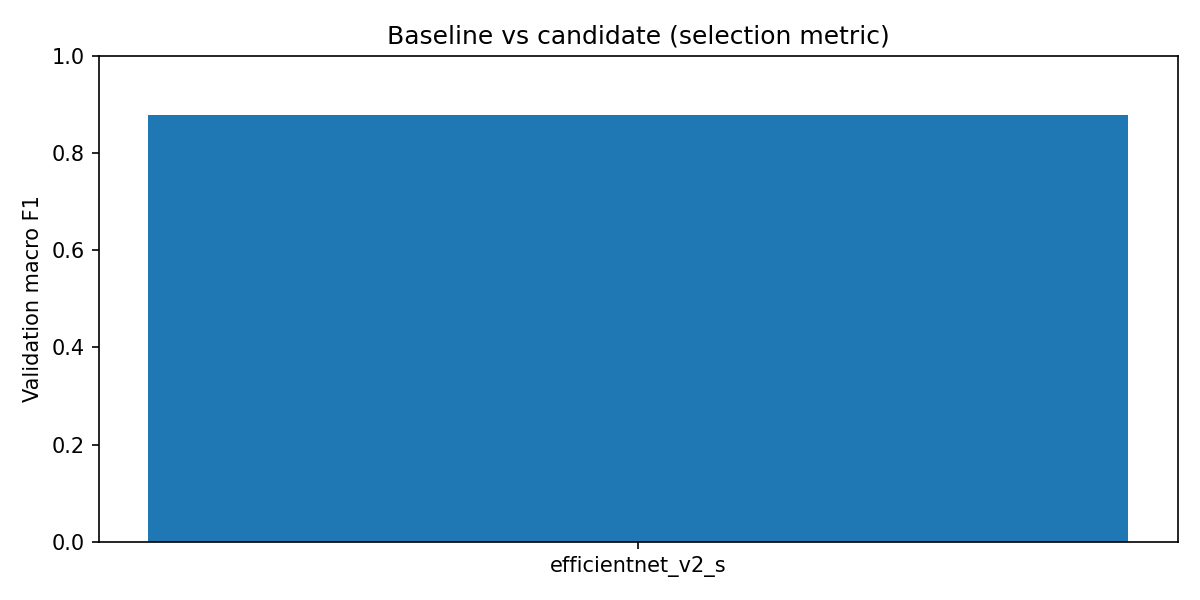

efficientnet_v2_s/test_per_class_accuracy.png


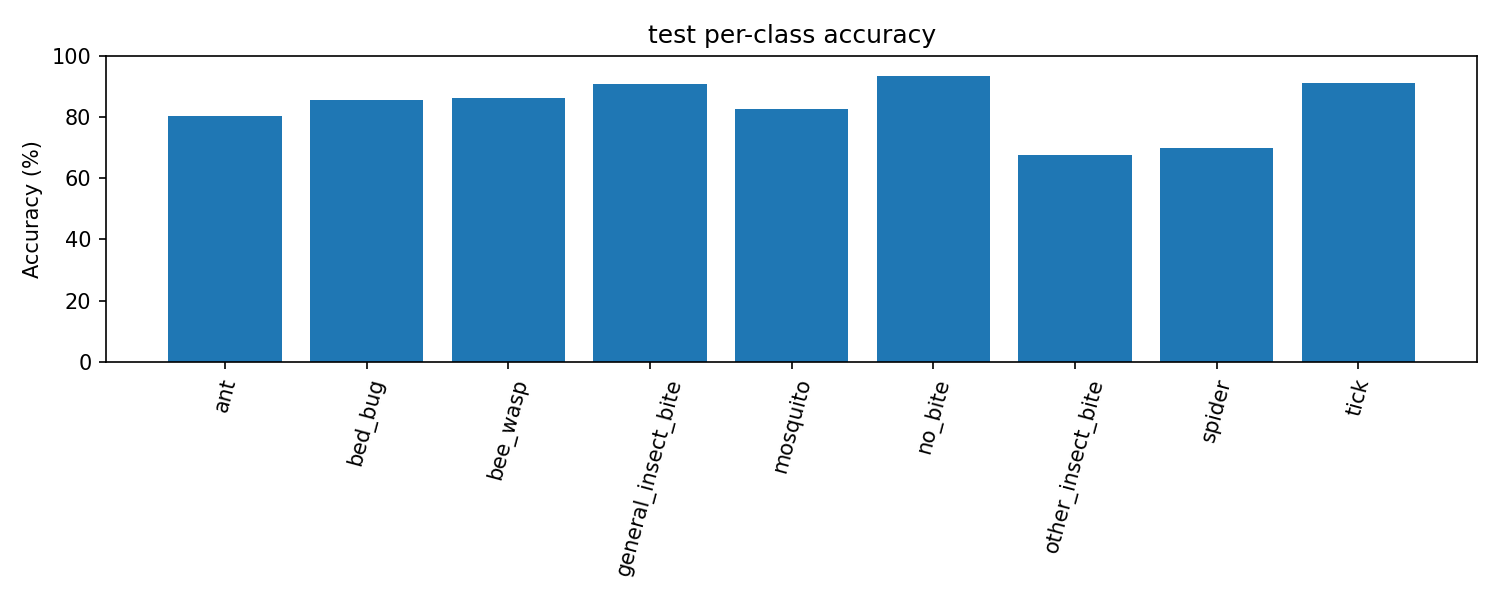

efficientnet_v2_s/test_confusion.png


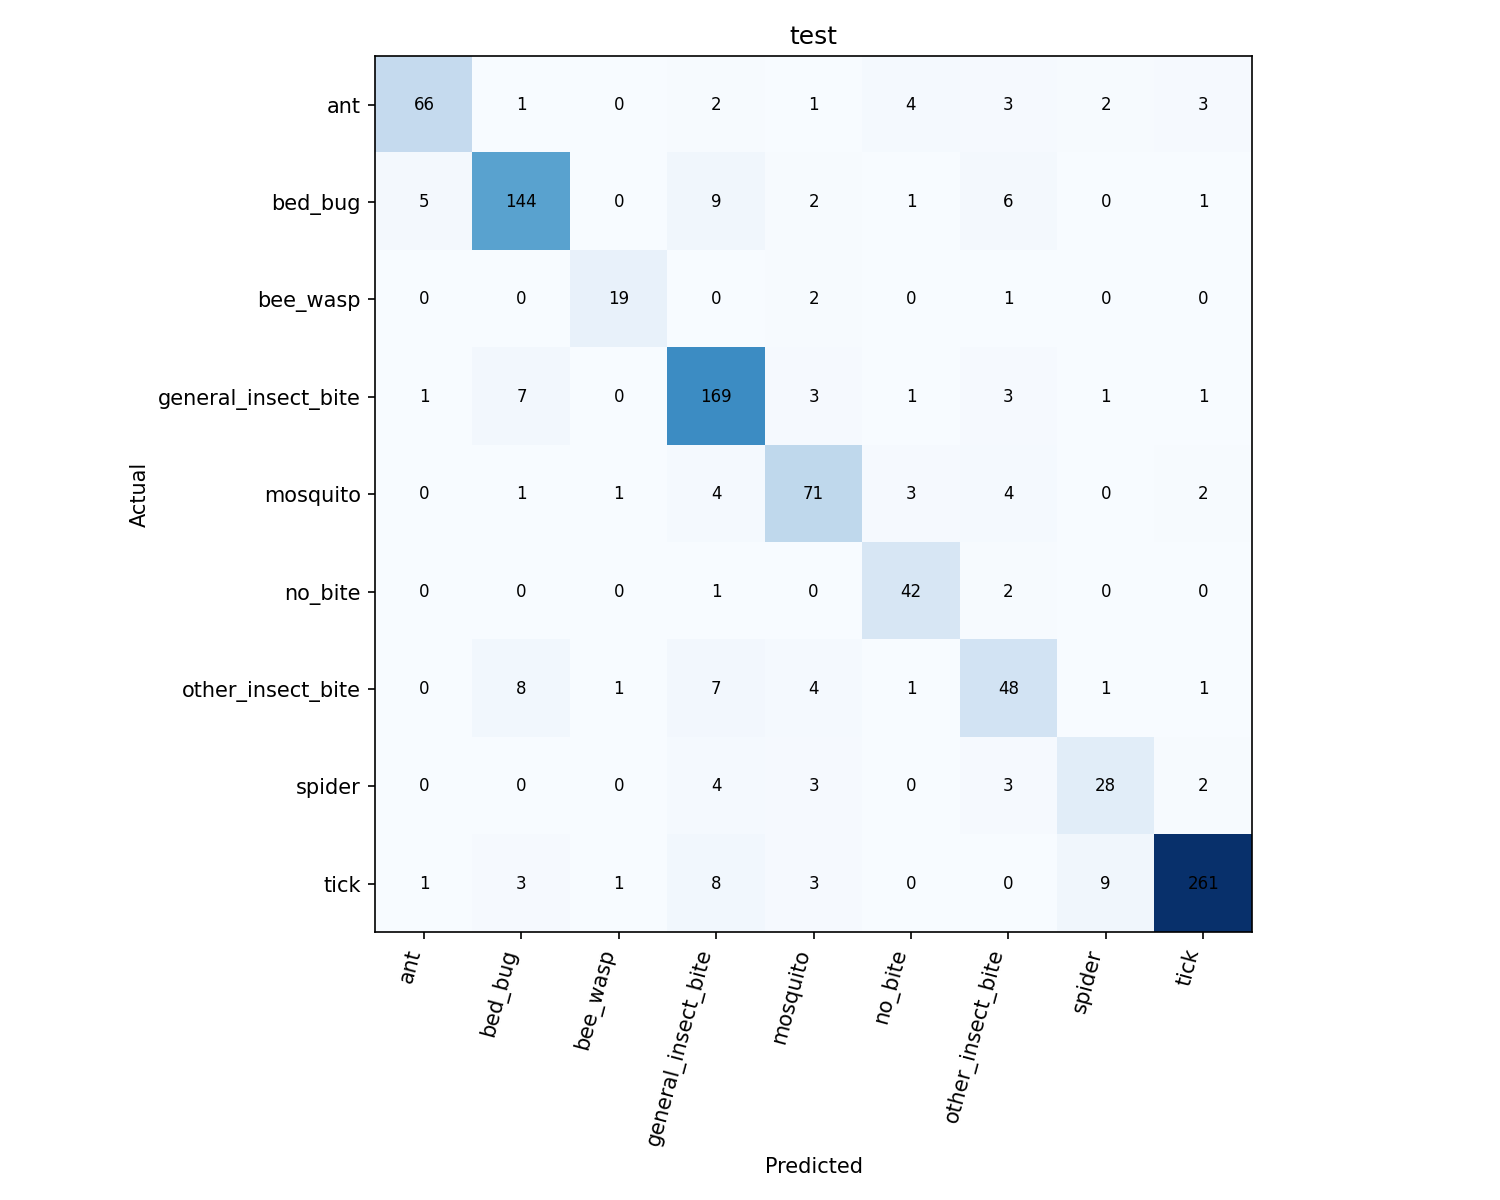


Files to download (Output tab / file browser):
  efficientnet_v2_s_inference.zip  75.7 MB
  selected_model_inference.zip  75.7 MB
Selected model: efficientnet_v2_s


In [11]:
import pandas as pd
from IPython.display import Image as IPImage, display
out = ctx['output']
for key, title in [('validation', 'VALIDATION'), ('test', 'TEST')]:
    table = {r['name']: r[key]['per_class_accuracy'] for r in results if key in r}
    if table:
        df = (pd.DataFrame(table) * 100).round(2)
        df.index.name = 'class'
        df.loc['OVERALL accuracy'] = [round(100 * r[key]['accuracy'], 2) for r in results if key in r]
        print(f'\nPer-class accuracy (%) - {title}  (rows = classes, columns = models)')
        display(df)
        df.to_csv(out / f'per_class_accuracy_{key}_all_models.csv')
for pattern in ['comparison.png', 'efficientnet_v2_s/test_per_class_accuracy.png', 'efficientnet_v2_s/test_confusion.png']:
    f = out / pattern
    if f.exists():
        print(pattern); display(IPImage(filename=str(f)))
print('\nFiles to download (Output tab / file browser):')
for f in sorted(out.glob('*.zip')):
    print(f'  {f.name}  {f.stat().st_size/1e6:.1f} MB')
print('Selected model:', comparison['selection']['selected_model'])

In [12]:
import zipfile
from pathlib import Path
base = Path('/kaggle/working/run2')
skip = {'latest.pt', 'best.pt'}   # big training checkpoints; the model weights are also inside exports/ and the zips
out = Path('/kaggle/working/run2_essentials.zip')
with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(base.rglob('*')):
        if p.is_file() and p.name not in skip:
            z.write(p, p.relative_to(base))
print('created', out, round(out.stat().st_size / 1e6, 1), 'MB')

created /kaggle/working/run2_essentials.zip 229.3 MB
